# Full-frame NFFA random-mask inpainting

This notebook benchmarks the trained 128 × 128 `sem_nffa_all10` PnP-Flow prior on one clean, full-resolution raw SEM frame. The raw frame is the ground truth. A single fixed global mask removes 70% of pixels, the frame is reconstructed through overlapping model-sized tiles, tile predictions are Hann-blended, and metrics are computed only on the synthetically missing pixels.

Mask convention throughout: `known_mask=True` means observed and data-consistent; `missing_mask=True` means removed and reconstructed.

In [1]:
from pathlib import Path
import csv
import json
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    repo_root = repo_root.parent
if not (repo_root / 'pnpflow').is_dir():
    raise RuntimeError('Open this notebook from the PnP-Flow repository or its notebooks/ directory.')
os.chdir(repo_root)

from pnpflow.utils import define_model

# Model and input. Resolve the raw frame directly from source_manifest.csv so
# the benchmark cannot accidentally use a training or validation source.
DATASET_NAME = 'sem_nffa_all10'
RUN_NAME = '20260713_112747_sem_nffa_all10_ot'
CHECKPOINT_PATH = repo_root / 'model' / DATASET_NAME / 'ot' / RUN_NAME / 'model_final.pt'
RAW_SEM_ROOT = Path('/data2/marci/bselvaku/nffa_sem/raw_images')
SOURCE_MANIFEST_PATH = repo_root / 'data' / DATASET_NAME / 'source_manifest.csv'
TEST_SOURCE_INDEX = 0  # Choose another held-out source by changing this index.

with SOURCE_MANIFEST_PATH.open(newline='', encoding='utf-8') as handle:
    test_source_rows = [row for row in csv.DictReader(handle) if row['split'] == 'test']
if not test_source_rows:
    raise RuntimeError(f'No test sources were found in {SOURCE_MANIFEST_PATH}')
if not 0 <= TEST_SOURCE_INDEX < len(test_source_rows):
    raise IndexError(f'TEST_SOURCE_INDEX={TEST_SOURCE_INDEX}; valid range is 0:{len(test_source_rows)}')
RAW_SOURCE_ROW = test_source_rows[TEST_SOURCE_INDEX]
if RAW_SOURCE_ROW['split'] != 'test':
    raise RuntimeError(f"Refusing non-test source with split={RAW_SOURCE_ROW['split']}")
RAW_SOURCE_RELATIVE = Path(RAW_SOURCE_ROW['source'])
RAW_SEM_IMAGE = RAW_SEM_ROOT / RAW_SOURCE_RELATIVE

# Match scripts/test_sem_nffa_all10_random_inpainting.sh.
MISSING_FRACTION = 0.70
MASK_SEED = 42
NOISE_SEED = 0
NOISE_STD = 0.01
STEPS_PNP = 100
NUM_SAMPLES = 5
LR_PNP = 1.0
ALPHA = 0.01

# The checkpoint accepts 128 x 128 tensors. A 64-pixel stride gives 50% overlap.
TILE_SIZE = 128
TILE_STRIDE = 64
INFERENCE_BATCH_SIZE = 64
USE_MULTI_GPU = True
SELECTED_TILE_INDEX = None  # None selects the tile nearest the frame center.

OUTPUT_DIR = repo_root / 'results' / DATASET_NAME / 'ot' / 'full_raw_random_inpainting' / RAW_SEM_IMAGE.stem
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT_PATH.is_file(), f'Checkpoint not found: {CHECKPOINT_PATH}'
assert RAW_SEM_IMAGE.is_file(), f'Raw SEM image not found: {RAW_SEM_IMAGE}'
print(f'Repository: {repo_root}')
print(f'Checkpoint: {CHECKPOINT_PATH}')
print(f"Manifest split: {RAW_SOURCE_ROW['split']} ({len(test_source_rows):,} available test sources)")
print(f'Raw image: {RAW_SEM_IMAGE}')
print(f'Output directory: {OUTPUT_DIR}')

/data2/marci/bselvaku/conda/envs/torchlearn/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow
Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10/ot/20260713_112747_sem_nffa_all10_ot/model_final.pt
Manifest split: test (2,133 available test sources)
Raw image: /data2/marci/bselvaku/nffa_sem/raw_images/Biological/L7_2e35622323b48389237957bcbd0d801d.jpg
Output directory: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_random_inpainting/L7_2e35622323b48389237957bcbd0d801d


In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('This full-frame PnP benchmark requires a CUDA GPU.')

torch.manual_seed(0)
torch.cuda.manual_seed_all(0)

class ModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = TILE_SIZE

model, _ = define_model(ModelArgs())
state_dict = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.to(device).eval()

gpu_ids = list(range(torch.cuda.device_count()))
if USE_MULTI_GPU and len(gpu_ids) > 1:
    model = torch.nn.DataParallel(model, device_ids=gpu_ids, output_device=gpu_ids[0])
    print(f'Multi-GPU inference enabled on {len(gpu_ids)} GPUs: {gpu_ids}')
else:
    print(f'Single-GPU inference on {torch.cuda.get_device_name(0)}')
print(f'Primary device: {device}')

Multi-GPU inference enabled on 4 GPUs: [0, 1, 2, 3]
Primary device: cuda:0


In [3]:
# Match scripts/prepare_sem_patches.py exactly: convert to grayscale, compute
# source-level 1st/99th percentiles, clip, then map to [-1, 1].
with Image.open(RAW_SEM_IMAGE) as image:
    raw_sem = np.asarray(image.convert('L'), dtype=np.float32)
if raw_sem.ndim != 2 or not np.isfinite(raw_sem).all():
    raise ValueError(f'Expected a finite 2D grayscale frame, got {raw_sem.shape}')

height, width = raw_sem.shape
if height < TILE_SIZE or width < TILE_SIZE:
    raise ValueError(f'Raw frame {raw_sem.shape} is smaller than TILE_SIZE={TILE_SIZE}.')

low, high = np.percentile(raw_sem, (1, 99))
if not high > low:
    raise ValueError('The raw frame has no usable percentile intensity range.')
raw_clipped = np.clip(raw_sem, low, high).astype(np.float32)
raw_norm = (2.0 * (raw_clipped - low) / (high - low) - 1.0).astype(np.float32)

# One fixed mask is generated over the complete frame and later sliced into tiles.
mask_rng = np.random.default_rng(MASK_SEED)
missing_mask = mask_rng.random(raw_sem.shape) < MISSING_FRACTION
known_mask = ~missing_mask

# Adding noise only at known locations is mathematically equivalent to the main.py
# benchmark because H_adj removes noise at missing locations before every update.
noise_rng = np.random.default_rng(NOISE_SEED)
known_noise = noise_rng.normal(0.0, NOISE_STD, raw_sem.shape).astype(np.float32)
observed_norm = np.zeros_like(raw_norm, dtype=np.float32)
observed_norm[known_mask] = np.clip(raw_norm[known_mask] + known_noise[known_mask], -1.0, 1.0)

def denormalize(image_norm):
    return np.clip((image_norm + 1.0) * 0.5 * (high - low) + low, low, high)

observed_display = denormalize(observed_norm)
observed_display[missing_mask] = 0.0  # display-only: make missing samples visibly black

def tile_starts(length, tile_size=TILE_SIZE, stride=TILE_STRIDE):
    starts = list(range(0, length - tile_size + 1, stride))
    last = length - tile_size
    if starts[-1] != last:
        starts.append(last)
    return starts

tile_rows = tile_starts(height)
tile_cols = tile_starts(width)
tile_locations = [(top, left) for top in tile_rows for left in tile_cols]
tile_missing_fractions = np.array([
    missing_mask[top:top + TILE_SIZE, left:left + TILE_SIZE].mean()
    for top, left in tile_locations
], dtype=np.float32)

if SELECTED_TILE_INDEX is None:
    center_y, center_x = height / 2, width / 2
    SELECTED_TILE_INDEX = min(
        range(len(tile_locations)),
        key=lambda index: (
            tile_locations[index][0] + TILE_SIZE / 2 - center_y
        ) ** 2 + (
            tile_locations[index][1] + TILE_SIZE / 2 - center_x
        ) ** 2,
    )
if not 0 <= SELECTED_TILE_INDEX < len(tile_locations):
    raise IndexError(f'SELECTED_TILE_INDEX={SELECTED_TILE_INDEX} is outside 0:{len(tile_locations)}')

print(f'Raw frame: Y={height}, X={width}')
print(f'Normalization percentiles: low={low:.5g}, high={high:.5g}')
print(f'Global missing pixels: {missing_mask.sum():,}/{missing_mask.size:,} ({missing_mask.mean():.2%})')
print(f'Tiling: {len(tile_rows)} rows x {len(tile_cols)} columns = {len(tile_locations)} tiles')
print(
    f'Per-tile missing fraction: min={tile_missing_fractions.min():.2%}, '
    f'mean={tile_missing_fractions.mean():.2%}, max={tile_missing_fractions.max():.2%}'
)
print(f'Selected visualization tile: {SELECTED_TILE_INDEX} at (y, x)={tile_locations[SELECTED_TILE_INDEX]}')

Raw frame: Y=768, X=1024
Normalization percentiles: low=67, high=255
Global missing pixels: 550,624/786,432 (70.02%)
Tiling: 11 rows x 15 columns = 165 tiles
Per-tile missing fraction: min=68.96%, mean=70.04%, max=70.65%
Selected visualization tile: 82 at (y, x)=(320, 448)


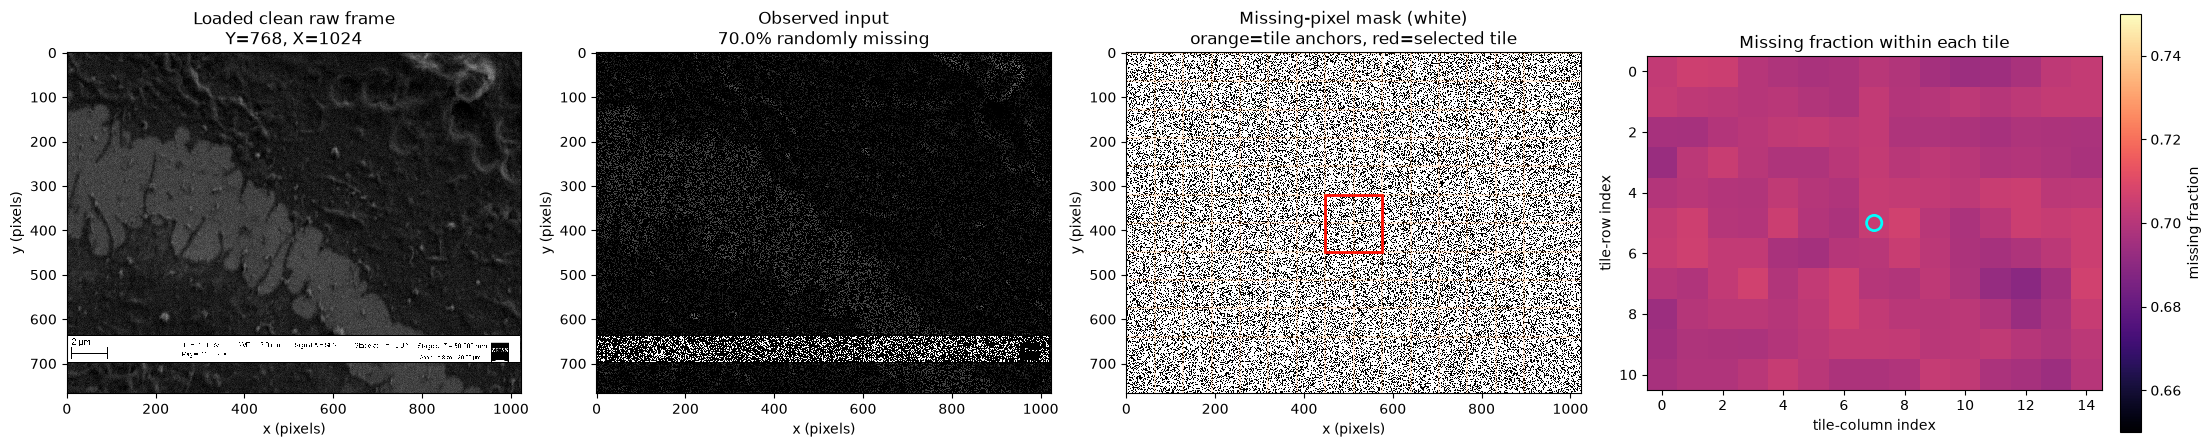

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_random_inpainting/L7_2e35622323b48389237957bcbd0d801d/full_frame_mask_and_tile_diagnostic.png


In [4]:
# Pre-inference mask visualization. The third panel shows the global missing mask
# with model-tile anchors; the fourth summarizes missingness inside every tile.
fig, axes = plt.subplots(1, 4, figsize=(22, 5), constrained_layout=True)

axes[0].imshow(raw_sem, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title(f'Loaded clean raw frame\nY={height}, X={width}')

axes[1].imshow(observed_display, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[1].set_title(f'Observed input\n{missing_mask.mean():.1%} randomly missing')

axes[2].imshow(missing_mask, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
for top in tile_rows:
    axes[2].axhline(top, color='tab:orange', linewidth=0.35, alpha=0.55)
for left in tile_cols:
    axes[2].axvline(left, color='tab:orange', linewidth=0.35, alpha=0.55)
selected_top, selected_left = tile_locations[SELECTED_TILE_INDEX]
axes[2].add_patch(plt.Rectangle(
    (selected_left, selected_top), TILE_SIZE, TILE_SIZE,
    fill=False, edgecolor='red', linewidth=2.0,
))
axes[2].set_title('Missing-pixel mask (white)\norange=tile anchors, red=selected tile')

fraction_grid = tile_missing_fractions.reshape(len(tile_rows), len(tile_cols))
heatmap = axes[3].imshow(fraction_grid, cmap='magma', vmin=0.65, vmax=0.75, interpolation='nearest')
axes[3].scatter(
    [SELECTED_TILE_INDEX % len(tile_cols)],
    [SELECTED_TILE_INDEX // len(tile_cols)],
    facecolors='none', edgecolors='cyan', s=120, linewidths=2,
)
axes[3].set_title('Missing fraction within each tile')
axes[3].set_xlabel('tile-column index')
axes[3].set_ylabel('tile-row index')
fig.colorbar(heatmap, ax=axes[3], fraction=0.046, pad=0.04, label='missing fraction')

for axis in axes[:3]:
    axis.set_xlabel('x (pixels)')
    axis.set_ylabel('y (pixels)')

mask_figure_path = OUTPUT_DIR / 'full_frame_mask_and_tile_diagnostic.png'
fig.savefig(mask_figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {mask_figure_path}')

In [5]:
@torch.inference_mode()
def pnp_flow_inpaint_tiles(observed, known):
    """Match PNP_FLOW.solve_ip for Gaussian inpainting with per-tile fixed masks."""
    known = known.to(device=observed.device, dtype=observed.dtype)
    x = known * observed
    lr = NOISE_STD ** 2 * LR_PNP

    for iteration in range(STEPS_PNP):
        t = torch.full((len(x),), iteration / STEPS_PNP, device=x.device)
        t_view = t.view(-1, 1, 1, 1)
        lr_t = lr * (1.0 - t).pow(ALPHA).view(-1, 1, 1, 1)

        # For a fixed binary inpainting operator, H and H_adj are both known * x.
        data_gradient = known * (known * x - observed) / (NOISE_STD ** 2)
        z = x - lr_t * data_gradient

        x_new = torch.zeros_like(x)
        for _ in range(NUM_SAMPLES):
            z_tilde = t_view * z + (1.0 - t_view) * torch.randn_like(z)
            velocity = model(z_tilde, t)
            x_new += z_tilde + (1.0 - t_view) * velocity
        x_new /= NUM_SAMPLES

        # Hard data consistency: only missing pixels receive prior predictions.
        x = known * observed + (1.0 - known) * x_new

    return x.clamp(-1.0, 1.0)

hann_1d = np.hanning(TILE_SIZE).astype(np.float32)
blend_window = np.outer(hann_1d, hann_1d)
# A small positive floor keeps image-border pixels covered where a Hann window is zero.
blend_window = np.maximum(blend_window / blend_window.max(), 1e-3).astype(np.float32)

def extract_tiles(image):
    return np.stack([
        image[top:top + TILE_SIZE, left:left + TILE_SIZE]
        for top, left in tile_locations
    ])

print('PnP tile solver and Hann blending window are ready.')

PnP tile solver and Hann blending window are ready.


In [6]:
clean_tiles = extract_tiles(raw_norm).astype(np.float32)
observed_tiles = extract_tiles(observed_norm).astype(np.float32)
known_tiles = extract_tiles(known_mask).astype(np.float32)
missing_tiles = ~known_tiles.astype(bool)
restored_tiles = np.empty_like(clean_tiles, dtype=np.float32)

number_of_batches = math.ceil(len(tile_locations) / INFERENCE_BATCH_SIZE)
inference_start = time.perf_counter()
for batch_number, offset in enumerate(range(0, len(tile_locations), INFERENCE_BATCH_SIZE), start=1):
    stop = min(offset + INFERENCE_BATCH_SIZE, len(tile_locations))
    batch_observed = torch.from_numpy(observed_tiles[offset:stop, None]).to(device)
    batch_known = torch.from_numpy(known_tiles[offset:stop, None]).to(device)
    batch_start = time.perf_counter()
    restored_tiles[offset:stop] = pnp_flow_inpaint_tiles(batch_observed, batch_known).cpu().numpy()[:, 0]
    batch_seconds = time.perf_counter() - batch_start
    print(
        f'Completed tile batch {batch_number}/{number_of_batches}: '
        f'tiles {offset}:{stop} in {batch_seconds:.1f} s'
    )
    del batch_observed, batch_known
    torch.cuda.empty_cache()

inference_seconds = time.perf_counter() - inference_start
print(f'All {len(tile_locations)} tiles reconstructed in {inference_seconds:.1f} s.')

# Blend only predictions for missing pixels. Observed pixels are restored afterward
# directly from observed_norm, so the final frame is exactly data-consistent.
reconstruction_sum = np.zeros_like(raw_norm, dtype=np.float32)
reconstruction_weight = np.zeros_like(raw_norm, dtype=np.float32)
for restored_tile, missing_tile, (top, left) in zip(restored_tiles, missing_tiles, tile_locations):
    target = np.s_[top:top + TILE_SIZE, left:left + TILE_SIZE]
    weights = blend_window * missing_tile.astype(np.float32)
    reconstruction_sum[target] += restored_tile * weights
    reconstruction_weight[target] += weights

uncovered = missing_mask & (reconstruction_weight <= 0)
if uncovered.any():
    raise RuntimeError(f'{uncovered.sum():,} missing pixels were not covered by an inference tile.')

reconstruction_norm = observed_norm.copy()
reconstruction_norm[missing_mask] = (
    reconstruction_sum[missing_mask] / reconstruction_weight[missing_mask]
)
reconstruction_norm = np.clip(reconstruction_norm, -1.0, 1.0)
reconstruction_raw = denormalize(reconstruction_norm).astype(np.float32)

known_consistency = np.max(np.abs(reconstruction_norm[known_mask] - observed_norm[known_mask]))
print(f'Maximum known-pixel consistency error: {known_consistency:.3e}')
print(f'All {missing_mask.sum():,} missing pixels received blended predictions.')

Completed tile batch 1/3: tiles 0:64 in 215.5 s
Completed tile batch 2/3: tiles 64:128 in 210.5 s
Completed tile batch 3/3: tiles 128:165 in 119.8 s
All 165 tiles reconstructed in 545.9 s.
Maximum known-pixel consistency error: 0.000e+00
All 550,624 missing pixels received blended predictions.


In [7]:
clean_01 = (raw_norm + 1.0) * 0.5
observed_01 = (observed_norm + 1.0) * 0.5
reconstruction_01 = (reconstruction_norm + 1.0) * 0.5

def masked_psnr(reference, estimate, mask):
    mse = np.mean((reference[mask] - estimate[mask]) ** 2)
    return float(10.0 * np.log10(1.0 / max(float(mse), 1e-12)))

def full_psnr(reference, estimate):
    mse = np.mean((reference - estimate) ** 2)
    return float(10.0 * np.log10(1.0 / max(float(mse), 1e-12)))

metrics = {
    'raw_image': str(RAW_SEM_IMAGE),
    'source_relative_path': RAW_SOURCE_RELATIVE.as_posix(),
    'source_split': RAW_SOURCE_ROW['split'],
    'height': int(height),
    'width': int(width),
    'normalization_low': float(low),
    'normalization_high': float(high),
    'missing_fraction': float(missing_mask.mean()),
    'tile_size': TILE_SIZE,
    'tile_stride': TILE_STRIDE,
    'tile_count': len(tile_locations),
    'steps_pnp': STEPS_PNP,
    'num_samples': NUM_SAMPLES,
    'alpha': ALPHA,
    'noise_std': NOISE_STD,
    'inference_seconds': float(inference_seconds),
    'observed_missing_psnr_db': masked_psnr(clean_01, observed_01, missing_mask),
    'reconstruction_missing_psnr_db': masked_psnr(clean_01, reconstruction_01, missing_mask),
    'reconstruction_full_psnr_db': full_psnr(clean_01, reconstruction_01),
    'missing_region_mae_normalized_01': float(np.mean(np.abs(clean_01[missing_mask] - reconstruction_01[missing_mask]))),
    'maximum_known_consistency_error': float(known_consistency),
}

try:
    from skimage.metrics import structural_similarity
    metrics['reconstruction_full_ssim'] = float(structural_similarity(
        clean_01, reconstruction_01, data_range=1.0,
    ))
except Exception as error:
    metrics['reconstruction_full_ssim'] = None
    print(f'SSIM was skipped: {error}')

for key, value in metrics.items():
    print(f'{key}: {value}')

np.save(OUTPUT_DIR / 'clean_raw_float32.npy', raw_sem.astype(np.float32))
np.save(OUTPUT_DIR / 'observed_normalized_float32.npy', observed_norm.astype(np.float32))
np.save(OUTPUT_DIR / 'missing_mask_uint8.npy', missing_mask.astype(np.uint8))
np.save(OUTPUT_DIR / 'reconstruction_normalized_float32.npy', reconstruction_norm.astype(np.float32))
np.save(OUTPUT_DIR / 'reconstruction_raw_float32.npy', reconstruction_raw.astype(np.float32))
with (OUTPUT_DIR / 'metrics.json').open('w', encoding='utf-8') as handle:
    json.dump(metrics, handle, indent=2)
print(f'Saved arrays and metrics to: {OUTPUT_DIR}')

raw_image: /data2/marci/bselvaku/nffa_sem/raw_images/Biological/L7_2e35622323b48389237957bcbd0d801d.jpg
source_relative_path: Biological/L7_2e35622323b48389237957bcbd0d801d.jpg
source_split: test
height: 768
width: 1024
normalization_low: 67.0
normalization_high: 255.0
missing_fraction: 0.7001546223958334
tile_size: 128
tile_stride: 64
tile_count: 165
steps_pnp: 100
num_samples: 5
alpha: 0.01
noise_std: 0.01
inference_seconds: 545.9226324139163
observed_missing_psnr_db: 8.49942414690678
reconstruction_missing_psnr_db: 29.56272468935407
reconstruction_full_psnr_db: 31.070540929091027
missing_region_mae_normalized_01: 0.023699596524238586
maximum_known_consistency_error: 0.0
reconstruction_full_ssim: 0.7443212789189146
Saved arrays and metrics to: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_random_inpainting/L7_2e35622323b48389237957bcbd0d801d


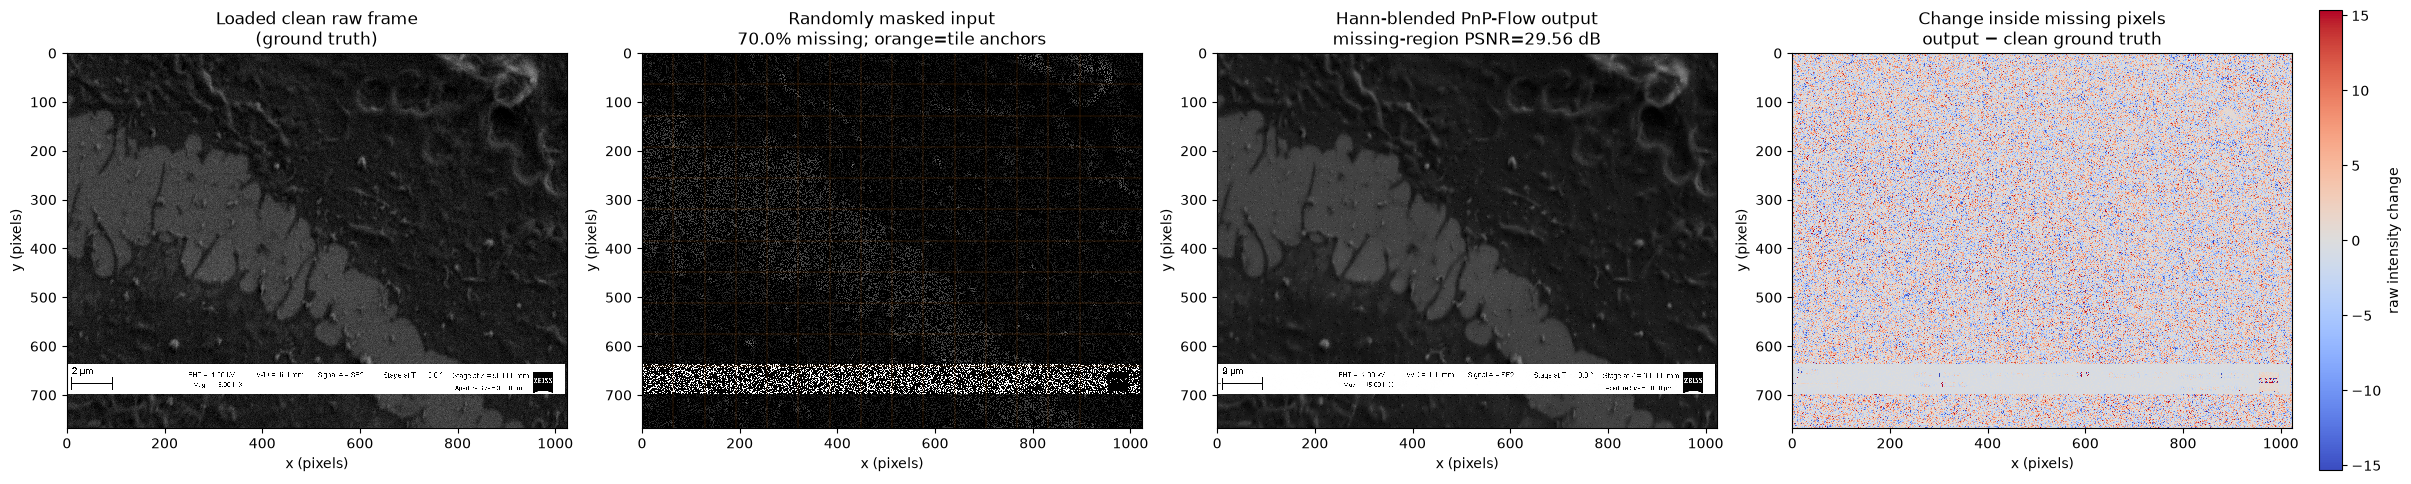

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_random_inpainting/L7_2e35622323b48389237957bcbd0d801d/full_frame_four_panel_comparison.png


In [8]:
# Full-frame four-panel comparison requested for visual inspection.
# The second panel combines the visibly masked input with tile anchors.
change_inside_mask = np.zeros_like(raw_sem, dtype=np.float32)
change_inside_mask[missing_mask] = reconstruction_raw[missing_mask] - raw_clipped[missing_mask]
change_limit = max(float(np.percentile(np.abs(change_inside_mask[missing_mask]), 99)), 1e-6)

fig, axes = plt.subplots(1, 4, figsize=(24, 6), constrained_layout=True)
axes[0].imshow(raw_sem, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title('Loaded clean raw frame\n(ground truth)')

axes[1].imshow(observed_display, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
for top in tile_rows:
    axes[1].axhline(top, color='tab:orange', linewidth=0.3, alpha=0.4)
for left in tile_cols:
    axes[1].axvline(left, color='tab:orange', linewidth=0.3, alpha=0.4)
axes[1].set_title(f'Randomly masked input\n{missing_mask.mean():.1%} missing; orange=tile anchors')

axes[2].imshow(reconstruction_raw, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[2].set_title(
    'Hann-blended PnP-Flow output\n'
    f"missing-region PSNR={metrics['reconstruction_missing_psnr_db']:.2f} dB"
)

change_plot = axes[3].imshow(
    change_inside_mask, cmap='coolwarm', vmin=-change_limit, vmax=change_limit,
    interpolation='nearest',
)
axes[3].set_title('Change inside missing pixels\noutput − clean ground truth')
fig.colorbar(change_plot, ax=axes[3], fraction=0.046, pad=0.04, label='raw intensity change')

for axis in axes:
    axis.set_xlabel('x (pixels)')
    axis.set_ylabel('y (pixels)')

comparison_path = OUTPUT_DIR / 'full_frame_four_panel_comparison.png'
fig.savefig(comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {comparison_path}')

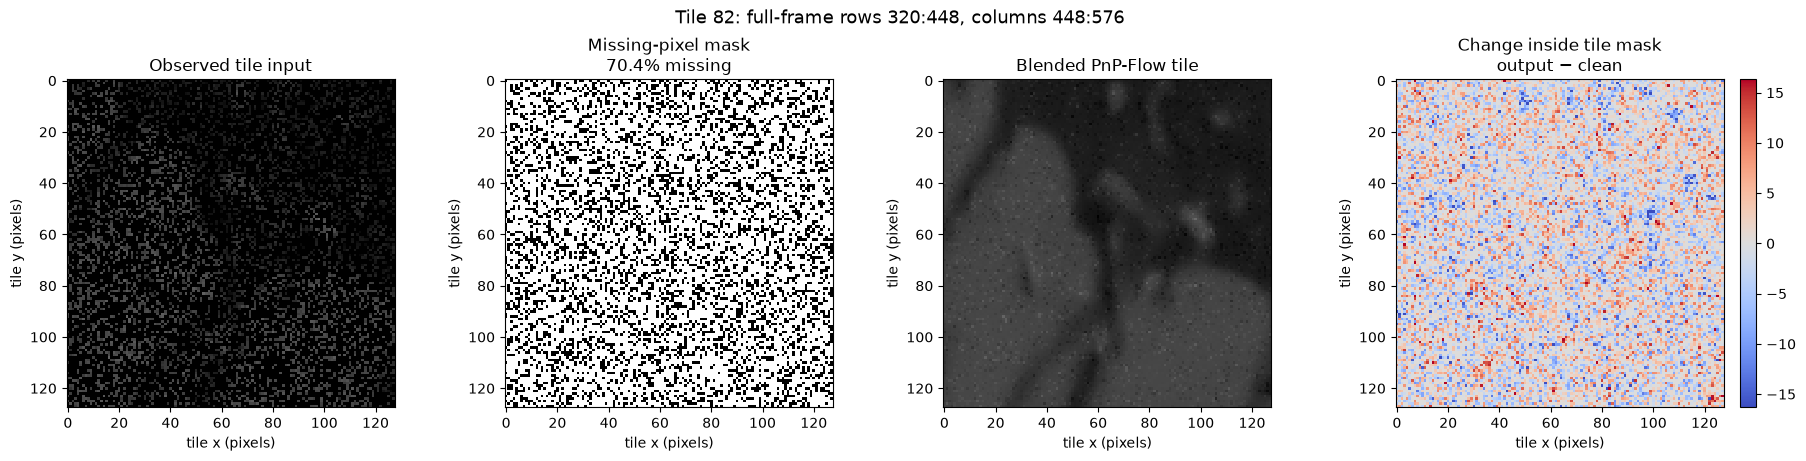

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_random_inpainting/L7_2e35622323b48389237957bcbd0d801d/tile_082_four_panel_comparison.png


In [9]:
# Selectable per-tile four-panel comparison. Change SELECTED_TILE_INDEX in the
# configuration cell and rerun this cell to inspect another tile.
tile_top, tile_left = tile_locations[SELECTED_TILE_INDEX]
tile_slice = np.s_[tile_top:tile_top + TILE_SIZE, tile_left:tile_left + TILE_SIZE]
selected_missing = missing_mask[tile_slice]
selected_observed = observed_display[tile_slice]
selected_reconstruction = reconstruction_raw[tile_slice]
selected_clean = raw_clipped[tile_slice]
selected_change = np.zeros((TILE_SIZE, TILE_SIZE), dtype=np.float32)
selected_change[selected_missing] = (
    selected_reconstruction[selected_missing] - selected_clean[selected_missing]
)
selected_limit = max(float(np.percentile(np.abs(selected_change[selected_missing]), 99)), 1e-6)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)
axes[0].imshow(selected_observed, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title('Observed tile input')
axes[1].imshow(selected_missing, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
axes[1].set_title(f'Missing-pixel mask\n{selected_missing.mean():.1%} missing')
axes[2].imshow(selected_reconstruction, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[2].set_title('Blended PnP-Flow tile')
tile_change_plot = axes[3].imshow(
    selected_change, cmap='coolwarm', vmin=-selected_limit, vmax=selected_limit,
    interpolation='nearest',
)
axes[3].set_title('Change inside tile mask\noutput − clean')
fig.colorbar(tile_change_plot, ax=axes[3], fraction=0.046, pad=0.04)

for axis in axes:
    axis.set_xlabel('tile x (pixels)')
    axis.set_ylabel('tile y (pixels)')
fig.suptitle(
    f'Tile {SELECTED_TILE_INDEX}: full-frame rows {tile_top}:{tile_top + TILE_SIZE}, '
    f'columns {tile_left}:{tile_left + TILE_SIZE}',
    fontsize=13,
)

tile_path = OUTPUT_DIR / f'tile_{SELECTED_TILE_INDEX:03d}_four_panel_comparison.png'
fig.savefig(tile_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {tile_path}')

## Interpretation

This benchmark measures distributed random missingness, not recovery of one contiguous damaged square. Every 128 × 128 tile retains roughly 30% spatially distributed observations, so every prediction is anchored by real local SEM structure. A large square can instead create fully missing tiles with no contextual measurements.